In [ ]:
!pip install -q gradio

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving best_cnn_baseline.keras to best_cnn_baseline.keras
Saving best_cnn_weighted.keras to best_cnn_weighted.keras


In [ ]:
import tensorflow as tf
import gradio as gr
from pathlib import Path

# Lokasi model
baseline_path = "/content/best_cnn_baseline.keras"
weighted_path = "/content/best_cnn_weighted.keras"

# Periksa keberadaan file
assert Path(baseline_path).exists(), "Model baseline tidak ditemukan!"
assert Path(weighted_path).exists(), "Model weighted tidak ditemukan!"

# Load model tanpa perlu training ulang
baseline_model = tf.keras.models.load_model(
    baseline_path,
    compile=False
)

weighted_model = tf.keras.models.load_model(
    weighted_path,
    compile=False
)

# Label kelas harus sama dengan Tugas 1
class_names = [
    "Coccidiosis",
    "Healthy",
    "New Castle Disease",
    "Salmonella"
]

print("=== MODEL CNN UTS ===")

print("Model Baseline: Berhasil dimuat")
print("Model Class Weighting: Berhasil dimuat")

print("\nInput Baseline:", baseline_model.input_shape)
print("Output Baseline:", baseline_model.output_shape)

print("\nInput Weighted:", weighted_model.input_shape)
print("Output Weighted:", weighted_model.output_shape)

print("\nJumlah kelas:", len(class_names))
print("Gradio Version:", gr.__version__)

=== MODEL CNN UTS ===
Model Baseline: Berhasil dimuat
Model Class Weighting: Berhasil dimuat

Input Baseline: (None, 224, 224, 3)
Output Baseline: (None, 4)

Input Weighted: (None, 224, 224, 3)
Output Weighted: (None, 4)

Jumlah kelas: 4
Gradio Version: 6.31.0


In [ ]:
import numpy as np
from PIL import Image, ImageOps

# Ukuran gambar sesuai training CNN
IMG_SIZE = (224, 224)

def preprocess_image(image):

    # Memastikan orientasi dan format RGB
    image = ImageOps.exif_transpose(image)
    image = image.convert("RGB")

    # Resize gambar
    image = image.resize(IMG_SIZE)

    # Konversi menjadi array
    image_array = np.array(
        image,
        dtype=np.float32
    )

    # Normalisasi piksel ke 0-1
    image_array = image_array / 255.0

    # Tambahkan dimensi batch
    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    return image_array

print("Fungsi preprocessing berhasil dibuat!")

Fungsi preprocessing berhasil dibuat!


In [ ]:
import pandas as pd

def predict_chicken_disease(image):

    # Preprocessing
    processed_image = preprocess_image(image)

    # Prediksi CNN Baseline
    baseline_probs = baseline_model.predict(
        processed_image,
        verbose=0
    )[0]

    # Prediksi CNN Class Weighting
    weighted_probs = weighted_model.predict(
        processed_image,
        verbose=0
    )[0]

    # Mengambil indeks prediksi tertinggi
    baseline_index = np.argmax(baseline_probs)
    weighted_index = np.argmax(weighted_probs)

    # Mengambil nama kelas
    baseline_label = class_names[baseline_index]
    weighted_label = class_names[weighted_index]

    # Mengambil confidence
    baseline_conf = float(
        baseline_probs[baseline_index]
    )

    weighted_conf = float(
        weighted_probs[weighted_index]
    )

    # Tabel probabilitas semua kelas
    probability_table = pd.DataFrame({
        "Kelas": class_names,
        "CNN Baseline (%)": baseline_probs * 100,
        "CNN Class Weighting (%)": weighted_probs * 100
    })

    probability_table = probability_table.round(2)

    return {
        "baseline_label": baseline_label,
        "baseline_confidence": baseline_conf,
        "weighted_label": weighted_label,
        "weighted_confidence": weighted_conf,
        "probabilities": probability_table
    }

print("Fungsi prediksi CNN berhasil dibuat!")

Fungsi prediksi CNN berhasil dibuat!


Upload satu gambar feses ayam:


Saving sample.jpg to sample.jpg


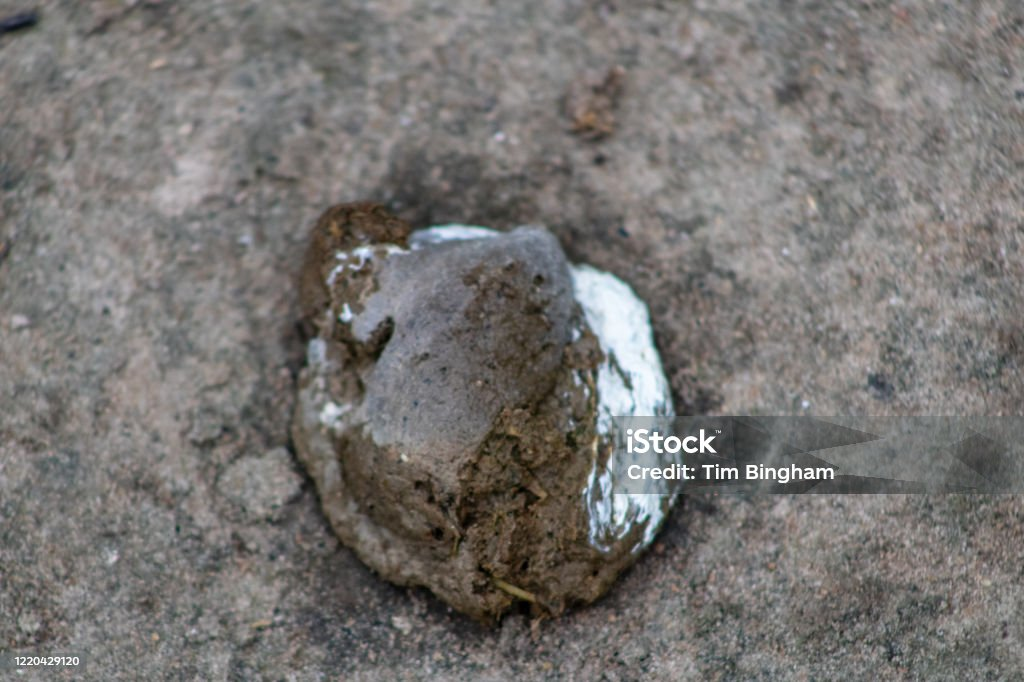

Gambar berhasil dibaca: sample.jpg


In [ ]:
from google.colab import files
from PIL import Image
from io import BytesIO

print("Upload satu gambar feses ayam:")

test_uploaded = files.upload()

# Ambil file pertama
filename = next(iter(test_uploaded))

# Membuka gambar
test_image = Image.open(
    BytesIO(test_uploaded[filename])
)

# Menampilkan gambar
display(test_image)

print("Gambar berhasil dibaca:", filename)

In [ ]:
# Jalankan prediksi
result = predict_chicken_disease(test_image)

print("=== HASIL PREDIKSI CNN ===")

print("\nCNN BASELINE")
print("Prediksi:", result["baseline_label"])
print(
    "Confidence:",
    f'{result["baseline_confidence"] * 100:.2f}%'
)

print("\nCNN CLASS WEIGHTING")
print("Prediksi:", result["weighted_label"])
print(
    "Confidence:",
    f'{result["weighted_confidence"] * 100:.2f}%'
)

print("\n=== PROBABILITAS SETIAP KELAS ===")
display(result["probabilities"])

=== HASIL PREDIKSI CNN ===

CNN BASELINE
Prediksi: Salmonella
Confidence: 70.73%

CNN CLASS WEIGHTING
Prediksi: Salmonella
Confidence: 56.25%

=== PROBABILITAS SETIAP KELAS ===


,Kelas,CNN Baseline (%),CNN Class Weighting (%)
0,Coccidiosis,0.340000,2.12
1,Healthy,26.700001,41.52
2,New Castle Disease,2.220000,0.11
3,Salmonella,70.730003,56.25


In [ ]:
import tensorflow as tf
import numpy as np
from PIL import ImageOps

def preprocess_image(image):
    image = ImageOps.exif_transpose(image).convert("RGB")

    image_array = np.asarray(image)

    image_tensor = tf.image.resize(
        image_array,
        [224, 224],
        method="bilinear"
    )

    image_tensor = tf.cast(
        image_tensor, tf.float32
    ) / 255.0

    return tf.expand_dims(
        image_tensor, axis=0
    ).numpy()

print("Preprocessing aplikasi siap!")

Preprocessing aplikasi siap!


In [ ]:
import gradio as gr

# Fungsi penghubung model dengan aplikasi
def predict_gradio(image):

    if image is None:
        raise gr.Error("Silakan upload gambar terlebih dahulu!")

    # Prediksi menggunakan fungsi Tahap 2
    result = predict_chicken_disease(image)

    # Hasil CNN Baseline
    baseline_text = (
        f"### {result['baseline_label']}\n"
        f"Confidence: "
        f"**{result['baseline_confidence'] * 100:.2f}%**"
    )

    # Hasil CNN Class Weighting
    weighted_text = (
        f"### {result['weighted_label']}\n"
        f"Confidence: "
        f"**{result['weighted_confidence'] * 100:.2f}%**"
    )

    return (
        baseline_text,
        weighted_text,
        result["probabilities"]
    )


# Membuat tampilan aplikasi
with gr.Blocks(
    title="Chicken Disease Classification"
) as demo:

    gr.Markdown(
        """
        # Chicken Disease Classification
        ### Sistem Klasifikasi Penyakit Ayam Menggunakan CNN

        Upload gambar feses ayam untuk melihat hasil
        prediksi CNN Baseline dan CNN Class Weighting.
        """
    )

    with gr.Row():

        # Kolom upload gambar
        with gr.Column():

            image_input = gr.Image(
                label="Upload Gambar Feses Ayam",
                type="pil",
                sources=["upload"],
                image_mode="RGB",
                height=300
            )

            predict_button = gr.Button(
                "Prediksi Penyakit",
                variant="primary"
            )

        # Kolom hasil prediksi
        with gr.Column():

            gr.Markdown("### Hasil Klasifikasi")

            gr.Markdown("**CNN Baseline**")
            baseline_output = gr.Markdown()

            gr.Markdown("**CNN Class Weighting**")
            weighted_output = gr.Markdown()

    gr.Markdown("### Perbandingan Probabilitas Kelas")

    probability_output = gr.Dataframe(
        headers=[
            "Kelas",
            "CNN Baseline (%)",
            "CNN Class Weighting (%)"
        ],
        interactive=False,
        label="Probabilitas Prediksi"
    )

    gr.Markdown(
        """
        **Catatan:** Hasil klasifikasi merupakan prediksi
        berdasarkan citra, bukan diagnosis pasti.
        Pemeriksaan dokter hewan tetap diperlukan.
        """
    )

    # Menghubungkan tombol dengan fungsi prediksi
    predict_button.click(
        fn=predict_gradio,
        inputs=[image_input],
        outputs=[
            baseline_output,
            weighted_output,
            probability_output
        ]
    )

print("Antarmuka Gradio berhasil dibuat!")

Antarmuka Gradio berhasil dibuat!


In [ ]:
demo.launch(
    inline=True,
    debug=True
)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://4d899e369e2010336b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://4d899e369e2010336b.gradio.live


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Membuat model Grad-CAM
def build_gradcam_model(model):

    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = inputs
    last_conv_output = None

    for layer in model.layers:

        # Nonaktifkan augmentasi dan dropout
        if isinstance(
            layer,
            (tf.keras.Sequential, tf.keras.layers.Dropout)
        ):
            x = layer(x, training=False)
        else:
            x = layer(x)

        # Simpan output convolution terakhir
        if isinstance(layer, tf.keras.layers.Conv2D):
            last_conv_output = x

    if last_conv_output is None:
        raise ValueError("Layer Conv2D tidak ditemukan!")

    return tf.keras.Model(
        inputs,
        [last_conv_output, x]
    )


# Membuat Grad-CAM untuk kedua CNN
gradcam_baseline = build_gradcam_model(baseline_model)
gradcam_weighted = build_gradcam_model(weighted_model)

print("Grad-CAM CNN Baseline berhasil dibuat!")
print("Grad-CAM CNN Class Weighting berhasil dibuat!")

Grad-CAM CNN Baseline berhasil dibuat!
Grad-CAM CNN Class Weighting berhasil dibuat!


In [ ]:
def generate_gradcam(image, model_type="CNN Baseline"):

    # Preprocessing gambar
    image_batch = preprocess_image(image)

    # Pilih model
    if model_type == "CNN Baseline":
        grad_model = gradcam_baseline
    else:
        grad_model = gradcam_weighted

    # Hitung gradien
    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            tf.convert_to_tensor(image_batch),
            training=False
        )

        pred_index = tf.argmax(predictions[0])
        class_score = tf.gather(
            predictions[0], pred_index
        )

    gradients = tape.gradient(
        class_score, conv_outputs
    )

    if gradients is None:
        raise ValueError("Gradien tidak dapat dihitung.")

    # Bobot setiap channel
    weights = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    # Heatmap Grad-CAM
    heatmap = tf.reduce_sum(
        conv_outputs[0] * weights,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = tf.math.divide_no_nan(
        heatmap,
        tf.reduce_max(heatmap)
    )

    # Sesuaikan ukuran heatmap
    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        (224, 224)
    ).numpy()[:, :, 0]

    # Ubah heatmap menjadi gambar berwarna
    colored_heatmap = plt.get_cmap("jet")(
        heatmap
    )[:, :, :3]

    # Gambar asli setelah preprocessing
    original = image_batch[0]

    # Gabungkan gambar dengan heatmap
    overlay = np.clip(
        original * 0.65 +
        colored_heatmap * 0.35,
        0, 1
    )

    # Konversi menjadi gambar PIL
    heatmap_image = Image.fromarray(
        (colored_heatmap * 255).astype(np.uint8)
    )

    overlay_image = Image.fromarray(
        (overlay * 255).astype(np.uint8)
    )

    return heatmap_image, overlay_image


print("Fungsi visualisasi Grad-CAM berhasil dibuat!")

Fungsi visualisasi Grad-CAM berhasil dibuat!


In [32]:
import gradio as gr

# Tutup aplikasi sebelumnya jika masih berjalan
try:
    demo.close()
except NameError:
    pass


# Fungsi prediksi Gradio terbaru
def predict_gradio_v2(image, model_choice):

    if image is None:
        raise gr.Error("Silakan upload gambar terlebih dahulu!")

    # Prediksi kedua model
    result = predict_chicken_disease(image)

    baseline_text = (
        f"### {result['baseline_label']}\n"
        f"Confidence: **{result['baseline_confidence']:.2%}**"
    )

    weighted_text = (
        f"### {result['weighted_label']}\n"
        f"Confidence: **{result['weighted_confidence']:.2%}**"
    )

    # Rapikan tabel probabilitas
    table = result["probabilities"].copy()

    for col in [
        "CNN Baseline (%)",
        "CNN Class Weighting (%)"
    ]:
        table[col] = table[col].apply(
            lambda x: f"{x:.2f}%"
        )

    # Generate Grad-CAM
    heatmap, overlay = generate_gradcam(
        image, model_choice
    )

    return (
        baseline_text,
        weighted_text,
        table,
        heatmap,
        overlay
    )


# Membuat antarmuka terbaru
with gr.Blocks(
    title="Chicken Disease Classification - UTS"
) as demo_uts:

    gr.Markdown("""
    # Chicken Disease Classification
    ### Sistem Klasifikasi Penyakit Ayam Menggunakan CNN

    Upload citra feses ayam untuk membandingkan
    prediksi CNN Baseline dan CNN Class Weighting.
    """)

    with gr.Row():

        with gr.Column():

            image_input = gr.Image(
                label="Upload Gambar Feses Ayam",
                type="filepath",
                image_mode=None,
                sources=["upload"],
                height=300
            )
            model_choice = gr.Radio(
                choices=[
                    "CNN Baseline",
                    "CNN Class Weighting"
                ],
                value="CNN Baseline",
                label="Pilih Model untuk Visualisasi Grad-CAM"
            )

            predict_button = gr.Button(
                "Prediksi Penyakit",
                variant="primary"
            )

        with gr.Column():

            gr.Markdown("## Hasil Klasifikasi")

            gr.Markdown("**CNN Baseline**")
            baseline_output = gr.Markdown()

            gr.Markdown("**CNN Class Weighting**")
            weighted_output = gr.Markdown()

    gr.Markdown("## Perbandingan Probabilitas Kelas")

    probability_output = gr.Dataframe(
        label="Probabilitas Prediksi (%)",
        interactive=False
    )

    gr.Markdown("## Visualisasi Grad-CAM")

    with gr.Row():

        heatmap_output = gr.Image(
            label="Grad-CAM Heatmap",
            type="pil",
            height=280
        )

        overlay_output = gr.Image(
            label="Grad-CAM Overlay",
            type="pil",
            height=280
        )

    gr.Markdown("""
    **Catatan:** Sistem memberikan prediksi berbasis citra,
    bukan diagnosis pasti. Grad-CAM menunjukkan kontribusi
    relatif area gambar terhadap prediksi, bukan bukti
    bahwa model telah mengenali penyebab penyakit.
    """)

    predict_button.click(
        fn=predict_gradio_v2,
        inputs=[
            image_input,
            model_choice
        ],
        outputs=[
            baseline_output,
            weighted_output,
            probability_output,
            heatmap_output,
            overlay_output
        ]
    )

print("Aplikasi UTS dengan Grad-CAM berhasil dibuat!")

Aplikasi UTS dengan Grad-CAM berhasil dibuat!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip
Saving test.csv to test.csv


In [ ]:
from pathlib import Path
import zipfile
import pandas as pd

# Folder dataset
dataset_dir = Path("/content/chicken_dataset")
train_dir = dataset_dir / "Train"

# Ekstrak jika folder gambar belum tersedia
if not train_dir.exists():
    with zipfile.ZipFile("/content/archive.zip") as z:
        z.extractall(dataset_dir)

# Lokasi CSV testing
test_csv = Path("/content/test.csv")

if not test_csv.exists():
    test_csv = dataset_dir / "splits" / "test.csv"

# Membaca data
test_df = pd.read_csv(test_csv)

print("=== DATA TESTING ===")
print("Total gambar:", len(test_df))

print("\nDistribusi kelas:")
print(test_df["label"].value_counts())

print("\nContoh data:")
display(test_df.head())

=== DATA TESTING ===
Total gambar: 1168

Distribusi kelas:
label
Salmonella            372
Healthy               360
Coccidiosis           352
New Castle Disease     84
Name: count, dtype: int64

Contoh data:


,images,label,image_hash
0,salmo.1413.jpg,Salmonella,ba5a7b4a9e0b6a4457dae0692d47fb81c238be43f38da9...
1,pcrcocci.241.jpg,Coccidiosis,96b4e05e6449a6bd97b4bd67e065170b4b56c2c8231313...
2,cocci.193.jpg,Coccidiosis,483a67a837d33ad78e12064ce26fe0f133c467b7f22c9b...
3,cocci.1210.jpg,Coccidiosis,b10cfa715f1e8609232a5dbe8ea846ffb0c31826273916...
4,pcrcocci.366.jpg,Coccidiosis,1c5dc07a1c9b4c210b2ddb245f8a41704695b935afb428...


In [ ]:
import numpy as np
import tensorflow as tf

# Menyusun lokasi gambar testing
test_paths = [
    str(train_dir / filename)
    for filename in test_df["images"]
]

# Loader yang sama dengan preprocessing training
def load_test_image(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [224, 224])
    img = tf.cast(img, tf.float32) / 255.0
    return img

test_images_ds = tf.data.Dataset.from_tensor_slices(
    test_paths
).map(
    load_test_image,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(32).prefetch(tf.data.AUTOTUNE)

# Prediksi
probabilities = baseline_model.predict(test_images_ds)
prediction_indices = np.argmax(probabilities, axis=1)

test_results = test_df.copy()

test_results["prediksi"] = [
    class_names[i] for i in prediction_indices
]

test_results["confidence"] = (
    np.max(probabilities, axis=1) * 100
)

test_results["benar"] = (
    test_results["label"] == test_results["prediksi"]
)

# Pilih satu contoh benar dan salah
contoh_benar = test_results[
    test_results["benar"]
].sample(1, random_state=42)

contoh_salah = test_results[
    ~test_results["benar"]
].sample(1, random_state=42)

print("=== CONTOH PREDIKSI BENAR ===")
display(contoh_benar[
    ["images", "label", "prediksi", "confidence"]
])

print("\n=== CONTOH PREDIKSI SALAH ===")
display(contoh_salah[
    ["images", "label", "prediksi", "confidence"]
])

37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step
=== CONTOH PREDIKSI BENAR ===


,images,label,prediksi,confidence
285,healthy.1007.jpg,Healthy,Healthy,98.187561



=== CONTOH PREDIKSI SALAH ===


,images,label,prediksi,confidence
838,healthy.1620.jpg,Healthy,New Castle Disease,51.35873


In [ ]:
import zipfile
from google.colab import files

demo_zip = "/content/contoh_demo_uts.zip"

with zipfile.ZipFile(demo_zip, "w") as z:

    for kategori, row in [
        ("benar", contoh_benar.iloc[0]),
        ("salah", contoh_salah.iloc[0])
    ]:
        source = train_dir / row["images"]

        z.write(
            source,
            arcname=f"{kategori}_{row['images']}"
        )

        z.writestr(
            f"label_{kategori}.txt",
            f"Label asli: {row['label']}\n"
            f"Prediksi Baseline: {row['prediksi']}\n"
            f"Confidence: {row['confidence']:.2f}%"
        )

files.download(demo_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# Tutup aplikasi lama
if "demo" in globals():
    try:
        demo.close()
    except Exception:
        pass

if "demo_uts" in globals():
    try:
        demo_uts.close()
    except Exception:
        pass

print("Aplikasi Gradio sebelumnya sudah ditutup.")

Closing server running on port: 7860
Aplikasi Gradio sebelumnya sudah ditutup.


In [24]:
import time

print("Memulai aplikasi Gradio...")

start = time.perf_counter()

demo_uts.launch(
    inline=False,
    share=True,
    debug=False,
    show_error=True
)

print(
    f"Proses launch: {time.perf_counter() - start:.2f} detik"
)

Memulai aplikasi Gradio...
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c11c40b72b74261d84.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
Proses launch: 0.16 detik


In [26]:
# Jalankan aplikasi Gradio
app, local_url, public_url = demo_uts.launch(
    share=True,
    inline=False,
    debug=False,
    show_error=True,
    prevent_thread_lock=True
)

print("\n=== LINK APLIKASI TERBARU ===")
print("Public URL:", public_url)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4c3ecec8b0cd65e935.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)

=== LINK APLIKASI TERBARU ===
Public URL: https://4c3ecec8b0cd65e935.gradio.live


In [27]:
from PIL import Image
import tensorflow as tf
import numpy as np
from pathlib import Path

# Gambar yang sebelumnya salah diprediksi
image_path = Path(
    "/content/chicken_dataset/Train/healthy.1620.jpg"
)

if not image_path.exists():
    print("Gambar tidak ditemukan. Periksa folder dataset.")
else:
    # Metode asli saat evaluasi Tugas 1
    image_bytes = tf.io.read_file(str(image_path))
    img = tf.image.decode_jpeg(image_bytes, channels=3)
    img = tf.image.resize(img, [224, 224])
    img = tf.cast(img, tf.float32) / 255.0

    original_input = tf.expand_dims(img, axis=0)

    # Metode preprocessing aplikasi Gradio
    pil_image = Image.open(image_path)
    gradio_input = preprocess_image(pil_image)

    for name, data in [
        ("Preprocessing Tugas 1", original_input),
        ("Preprocessing Gradio", gradio_input)
    ]:
        probs = baseline_model.predict(data, verbose=0)[0]
        index = np.argmax(probs)

        print(f"\n=== {name} ===")
        print("Prediksi:", class_names[index])
        print(f"Confidence: {probs[index] * 100:.2f}%")


=== Preprocessing Tugas 1 ===
Prediksi: New Castle Disease
Confidence: 51.36%

=== Preprocessing Gradio ===
Prediksi: Healthy
Confidence: 45.05%


In [28]:
from PIL import Image
import tensorflow as tf
import numpy as np

path = "/content/chicken_dataset/Train/healthy.1620.jpg"

# Preprocessing Tugas 1
raw = tf.io.read_file(path)
img = tf.image.decode_jpeg(raw, channels=3)
img = tf.image.resize(img, [224, 224])
img = tf.cast(img, tf.float32) / 255.0
img = tf.expand_dims(img, 0)

# Preprocessing aplikasi
pil_img = Image.open(path)
img_app = preprocess_image(pil_img)

# Bandingkan hasil prediksi
for nama, data in [
    ("Tugas 1", img),
    ("Aplikasi Gradio", img_app)
]:
    pred = baseline_model.predict(data, verbose=0)[0]
    idx = np.argmax(pred)

    print(f"\n{nama}")
    print("Prediksi:", class_names[idx])
    print(f"Confidence: {pred[idx]*100:.2f}%")


Tugas 1
Prediksi: New Castle Disease
Confidence: 51.36%

Aplikasi Gradio
Prediksi: Healthy
Confidence: 45.05%


In [29]:
import tensorflow as tf
import numpy as np
from pathlib import Path

# Preprocessing yang konsisten dengan Tugas 1
def preprocess_image(image_path):

    image_path = str(image_path)

    # Baca file gambar asli
    image_bytes = tf.io.read_file(image_path)

    # Decode berdasarkan format gambar
    extension = Path(image_path).suffix.lower()

    if extension in [".jpg", ".jpeg"]:
        image = tf.image.decode_jpeg(
            image_bytes, channels=3
        )

    elif extension == ".png":
        image = tf.image.decode_png(
            image_bytes, channels=3
        )

    else:
        raise ValueError(
            "Format gambar harus JPG atau PNG."
        )

    # Resize dengan metode yang sama saat training
    image = tf.image.resize(
        image, [224, 224],
        method="bilinear"
    )

    # Normalisasi
    image = tf.cast(image, tf.float32) / 255.0

    # Tambahkan batch
    image = tf.expand_dims(image, axis=0)

    return image.numpy()

print("Preprocessing berhasil diperbaiki!")

Preprocessing berhasil diperbaiki!


In [33]:
try:
    demo_uts.close()
    print("Aplikasi lama berhasil ditutup!")
except Exception as e:
    print("Aplikasi lama tidak aktif:", e)

Aplikasi lama berhasil ditutup!


In [34]:
demo_uts.launch(
    inline=False,
    share=True,
    debug=False,
    show_error=True
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d69e678767b47887c9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
